# Sensitivity analysis: range vs. assumptions

One-at-a-time sweep: each assumption is varied over a plausible range while **all other inputs stay fixed at `base.json`**.

The fuel mass is held at the full tank from `base.json`. `az.evaluate` can't be used here: it sizes the fuel so the mission range + reserve is always met, so its range would be flat for every parameter.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

import ardea_sizer as az
from ardea_sizer.pipeline import evaluate_from_fuel_mass

base = az.load("base.json")
FUEL_MASS = base.masses.fuel.mass  # kg, held fixed for every sweep


def get_range_km(b) -> float:
    return float(evaluate_from_fuel_mass(b, fuel_mass=FUEL_MASS).range) / 1000


range_base = get_range_km(base)
print(f"Fuel mass: {FUEL_MASS:.2f} kg   baseline range: {range_base:.1f} km")

Fuel mass: 5.00 kg   baseline range: 825.9 km


## Sweep definitions

`dotted path in base.json: (label, min, max)`. Add engine or mission values the same way, e.g. `"engine.prop_eff"`.

In [2]:
SWEEPS = {
    "assumptions.c_l_max_3d":     ("$C_{L,max}$ (3D, clean)",  1.0,   1.8),
    "assumptions.delta_c_l_flap": ("$\Delta C_{L}$ flap",     0.0,   1.0),
    "assumptions.oswald_eff":     ("Oswald efficiency $e$",    0.6,   0.95),
    "assumptions.c_d_0":          ("$C_{D,0}$",                0.015, 0.035),
    "assumptions.wing_ar":        ("Aspect ratio $AR$",        3.0,   12.0),
    "assumptions.wing_tr":        ("Taper ratio $\lambda$",   0.2,   1.0),
}
N_POINTS = 25


def get_value(b, path):
    obj = b
    for part in path.split("."):
        obj = getattr(obj, part)
    return obj


results = {}
for path, (label, lo, hi) in SWEEPS.items():
    values = np.linspace(lo, hi, N_POINTS)
    ranges = np.array([get_range_km(base.with_(**{path: v})) for v in values])
    results[path] = pd.DataFrame({"value": values, "range_km": ranges})

pd.DataFrame(
    {
        "baseline": [get_value(base, p) for p in SWEEPS],
        "range at min [km]": [results[p].range_km.iloc[0] for p in SWEEPS],
        "range at max [km]": [results[p].range_km.iloc[-1] for p in SWEEPS],
    },
    index=[label for label, *_ in SWEEPS.values()],
).round(3)

,baseline,range at min [km],range at max [km]
"$C_{L,max}$ (3D, clean)",1.430,659.667,962.763
$\Delta C_{L}$ flap,0.590,596.091,977.181
Oswald efficiency $e$,0.800,815.923,830.718
"$C_{D,0}$",0.022,1190.203,526.953
Aspect ratio $AR$,5.000,806.186,843.984
Taper ratio $\lambda$,0.450,825.903,825.903


## Range vs. each assumption

Same y-axis on every panel so the slopes are directly comparable. Dot = baseline from `base.json`, dashed line = mission range, dotted line = mission range + reserve.

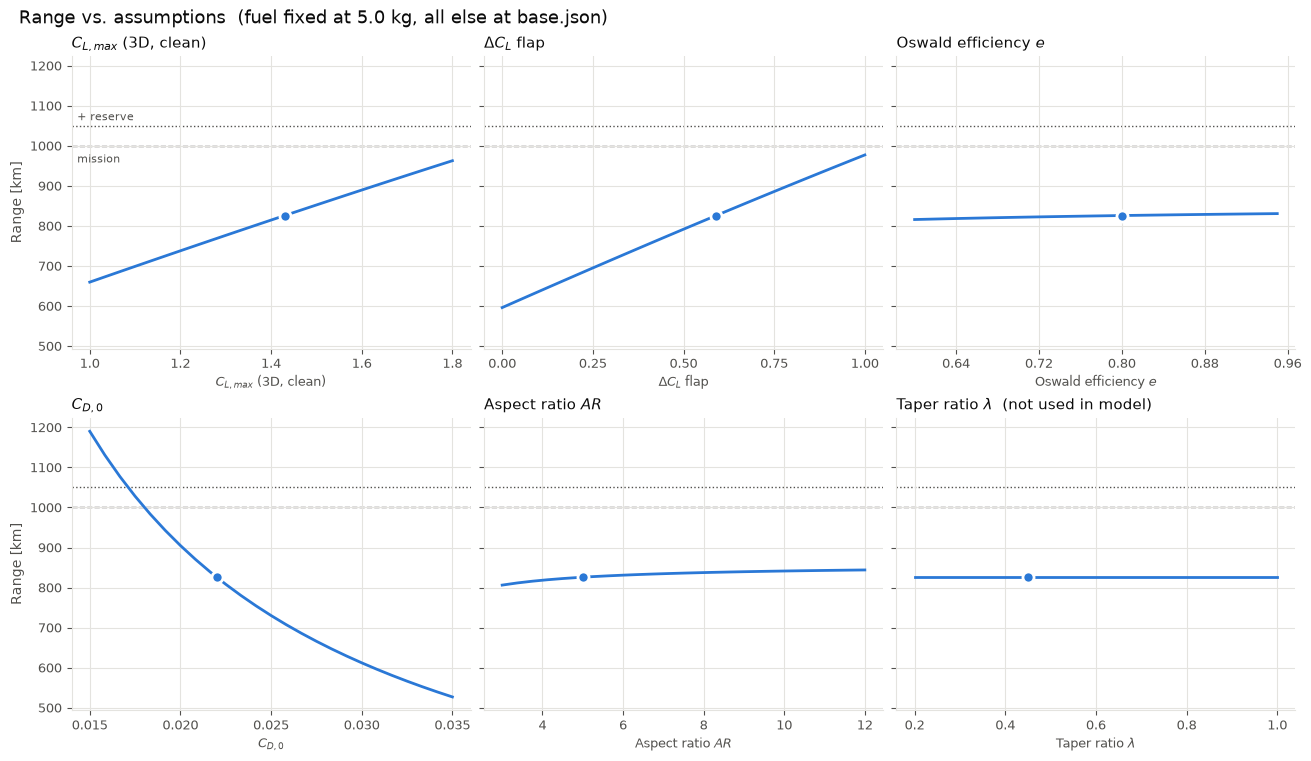

In [3]:
INK, INK_MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
SERIES = "#2a78d6"

target = base.mission.range / 1000
target_reserve = (base.mission.range + base.mission.reserve) / 1000

fig, axes = plt.subplots(2, 3, figsize=(13, 7.5), sharey=True, constrained_layout=True)

for ax, (path, (label, *_)) in zip(axes.flat, SWEEPS.items()):
    df = results[path]
    x0 = get_value(base, path)

    ax.axhline(target, color=INK_MUTED, lw=1, ls="--", zorder=1)
    ax.axhline(target_reserve, color=INK_MUTED, lw=1, ls=":", zorder=1)
    ax.plot(df.value, df.range_km, color=SERIES, lw=2, zorder=2)
    ax.plot(x0, range_base, "o", ms=8, color=SERIES, mec="white", mew=2, zorder=3)

    flat = np.ptp(df.range_km) < 1e-6
    ax.set_title(label + ("  (not used in model)" if flat else ""), color=INK, fontsize=11, loc="left")
    ax.set_xlabel(label, color=INK_MUTED, fontsize=9)
    ax.grid(color=GRID, lw=0.8)
    ax.tick_params(colors=INK_MUTED, labelsize=9)
    ax.xaxis.set_major_locator(MaxNLocator(5))
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)

for ax in axes[:, 0]:
    ax.set_ylabel("Range [km]", color=INK_MUTED)

axes.flat[0].annotate("mission", (axes.flat[0].get_xlim()[0], target), xytext=(4, -12),
                      textcoords="offset points", color=INK_MUTED, fontsize=8)
axes.flat[0].annotate("+ reserve", (axes.flat[0].get_xlim()[0], target_reserve), xytext=(4, 4),
                      textcoords="offset points", color=INK_MUTED, fontsize=8)

fig.suptitle(f"Range vs. assumptions  (fuel fixed at {FUEL_MASS:.1f} kg, all else at base.json)",
             color=INK, fontsize=13, x=0.01, ha="left")
plt.show()

## Which assumption matters most?

Elasticity at the baseline: **% change in range per 1 % change in the parameter** (central difference, ±1 %). Lets you compare parameters with different units.

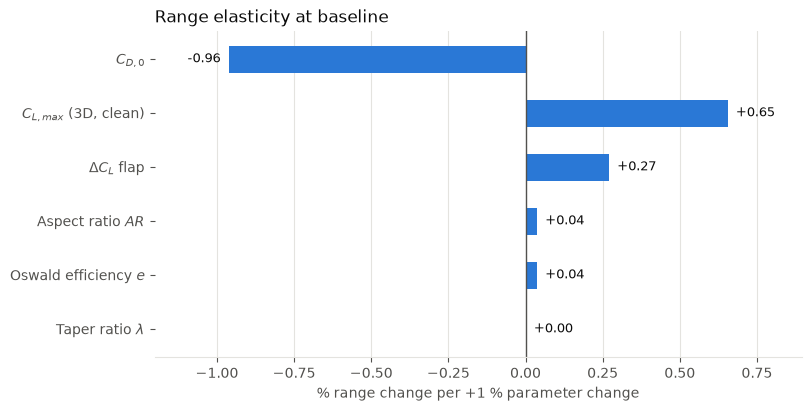

,elasticity
"$C_{D,0}$",-0.961
"$C_{L,max}$ (3D, clean)",0.655
$\Delta C_{L}$ flap,0.270
Aspect ratio $AR$,0.037
Oswald efficiency $e$,0.037
Taper ratio $\lambda$,0.000


In [4]:
STEP = 0.01

elasticity = {}
for path, (label, *_) in SWEEPS.items():
    x0 = get_value(base, path)
    r_up = get_range_km(base.with_(**{path: x0 * (1 + STEP)}))
    r_dn = get_range_km(base.with_(**{path: x0 * (1 - STEP)}))
    elasticity[label] = (r_up - r_dn) / range_base / (2 * STEP)

elasticity = pd.Series(elasticity).sort_values(key=np.abs)

fig, ax = plt.subplots(figsize=(8, 0.5 * len(elasticity) + 1), constrained_layout=True)
ax.barh(elasticity.index, elasticity.values, height=0.5, color=SERIES)
ax.axvline(0, color=INK_MUTED, lw=1)
for y, v in enumerate(elasticity.values):
    ax.annotate(f"{v:+.2f}", (v, y), xytext=(6 if v >= 0 else -6, 0), textcoords="offset points",
                ha="left" if v >= 0 else "right", va="center", color=INK, fontsize=9)
pad = 0.25 * np.abs(elasticity.values).max()
ax.set_xlim(min(elasticity.min(), 0) - pad, max(elasticity.max(), 0) + pad)
ax.set_xlabel("% range change per +1 % parameter change", color=INK_MUTED)
ax.set_title("Range elasticity at baseline", color=INK, loc="left")
ax.tick_params(colors=INK_MUTED)
ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
plt.show()

elasticity.iloc[::-1].round(3).to_frame("elasticity")